# Paper 1: How far can morphology concepts go? KG-guided hierarchical skin disease diagnosis

**Main task.** From the dermatologist-annotated concept vector $x\in\{0,1\}^{48}$, predict the **disease category** (9 classes, Fitzpatrick17k nine-partition). **Secondary**: super-category (3 classes) and fine-grained disease (113 classes, reported as top-5 differential).

**Why category level.** Section 3 quantifies the information ceiling of the concept input: it is low for 113 diseases but substantially higher for categories, and the KG's `IS_A` hierarchy maps directly onto this task.

**Model families**
1. **Flat baselines** trained on category labels: LR, Bernoulli NB, kNN (Jaccard), RF, gradient boosting, MLP (class-balanced variants in the grid)
2. **Bottom-up baselines**: the same models trained on diseases, probabilities summed into categories
3. **KG models**: KG-CatProfile (one profile per category), **KG-Mixture** (each category is a mixture of its diseases' hierarchically shrunk profiles, following `IS_A`), KG-Rule (chain scores mapped to categories)
4. **KG-Fusion**: base model + KG-Mixture + rule chain, weights tuned on val
5. **DermKG-Net**: GNN over the disease-level KG with a hierarchical loss

**Protocol.** Selection on val macro-F1; test used once. The category distribution is heavily skewed (inflammatory is about 65%), so **macro-F1 and balanced accuracy are the primary metrics**; accuracy is reported alongside the majority-class baseline and the ceiling.

In [40]:
# %pip install pandas numpy scikit-learn matplotlib torch -i https://pypi.tuna.tsinghua.edu.cn/simple

## 1. Config and imports

In [41]:
SKINCON_CSV = "image.csv"
F17K_CSV = "fitzpatrick17k.csv"
KG_DIR = "data/dermkg"              # output of dermkg_build.ipynb
OUT_DIR = "results/paper1_hier"
SEED = 42
GNN_SEEDS = [0, 1, 2]
N_BOOT = 1000
RUN_GNN = True

In [42]:
import os, ast, json, itertools, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score, top_k_accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

## 2. Data

In [43]:
sk = pd.read_csv(SKINCON_CSV).drop(columns=["Unnamed: 0"], errors="ignore")
sk = sk[sk["Do not consider this image"] == 0].drop(columns=["Do not consider this image"])
sk["md5"] = sk["ImageID"].str.replace(".jpg", "", regex=False)
CONCEPTS = [c for c in sk.columns if c not in ("ImageID", "md5")]
df = sk.merge(pd.read_csv(F17K_CSV), left_on="md5", right_on="md5hash", how="inner")
df = df.merge(pd.read_csv(os.path.join(KG_DIR, "split.csv"))[["md5", "split"]], on="md5").reset_index(drop=True)
df["skin_type"] = df["fitzpatrick_scale"].map(lambda v: f"FST-{int(v)}" if v in range(1, 7) else "FST-unknown")

DISEASES = sorted(df["label"].unique()); K = len(DISEASES); D_IDX = {d: i for i, d in enumerate(DISEASES)}
D2CAT = df.groupby("label")["nine_partition_label"].first().to_dict()
CAT2SUP = df.groupby("nine_partition_label")["three_partition_label"].first().to_dict()
CATS = sorted(set(D2CAT.values())); NC = len(CATS)
SUPS = sorted(set(CAT2SUP.values())); NS = len(SUPS)
d2c = np.array([CATS.index(D2CAT[d]) for d in DISEASES])
c2s = np.array([SUPS.index(CAT2SUP[c]) for c in CATS])
M_DC = np.eye(NC)[d2c]                     # K x NC: disease -> category (IS_A)
M_CS = np.eye(NS)[c2s]                     # NC x NS: category -> super (SUBCLASS_OF)

X = df[CONCEPTS].values.astype(np.float32)
yd = df["label"].map(D_IDX).values; yc = d2c[yd]; ys = c2s[yc]
tr, va, te = (df["split"].values == s for s in ("train", "val", "test"))
Xtr, Xva, Xte = X[tr], X[va], X[te]
print(f"train {tr.sum()} | val {va.sum()} | test {te.sum()} | diseases {K} | categories {NC} | supers {NS}")
dist = pd.DataFrame({"train": np.bincount(yc[tr], minlength=NC), "test": np.bincount(yc[te], minlength=NC)}, index=CATS)
dist["share"] = (dist["train"] / dist["train"].sum()).round(3)
display(dist.sort_values("train", ascending=False))

rules = pd.read_csv(os.path.join(KG_DIR, "clinical_rules.csv"))
rules["premise"] = rules["premise"].map(json.loads)
rules["targets"] = rules["targets"].map(ast.literal_eval)
triples = pd.read_csv(os.path.join(KG_DIR, "triples_infer.csv"))
assert not ((triples.relation == "DIAGNOSED_AS") & triples.split.isin(["val", "test"])).any(), "leakage!"

train 2259 | val 324 | test 647 | diseases 113 | categories 9 | supers 3


,train,test,share
inflammatory,1470,420,0.651
malignant epidermal,211,61,0.093
genodermatoses,152,44,0.067
benign epidermal,142,40,0.063
benign dermal,125,37,0.055
malignant melanoma,76,21,0.034
benign melanocyte,34,10,0.015
malignant cutaneous lymphoma,31,9,0.014
malignant dermal,18,5,0.008


## 3. Information ceiling of the concept input

For a model that only sees $x$, the best achievable accuracy is obtained by predicting the majority label of each distinct concept vector. The in-sample oracle (fit and scored on all 3,230 images) is an optimistic upper bound. Balanced accuracy has its own oracle: predict, for each vector, the label with the largest count divided by its class size.

In [44]:
key = np.array(["".join(map(str, r)) for r in X.astype(int)])
print(f"distinct concept vectors: {len(set(key))} / {len(key)}")
CEIL = {}
for lvl, lab, n in (("disease", yd, K), ("category", yc, NC), ("super", ys, NS)):
    tab = pd.crosstab(key, lab)
    acc = tab.max(1).sum() / len(lab)
    bal_pred = (tab / tab.sum(0)).idxmax(1)                 # oracle for balanced accuracy
    bal = balanced_accuracy_score(lab, bal_pred.loc[key].values)
    major = np.bincount(lab).max() / len(lab)
    CEIL[lvl] = dict(acc_ceiling=acc, balacc_ceiling=bal, majority_acc=major, chance_balacc=1 / n)
ceil = pd.DataFrame(CEIL).T.round(3)
display(ceil)
ceil.to_csv(os.path.join(OUT_DIR, "ceilings.csv"))
vc = pd.Series(key).value_counts()
print("most frequent vectors:")
for k, n in vc.head(5).items():
    print(f"  {n:4d} ({n / len(key):.1%})", [CONCEPTS[i] for i, ch in enumerate(k) if ch == "1"])

distinct concept vectors: 813 / 3230


,acc_ceiling,balacc_ceiling,majority_acc,chance_balacc
disease,0.389,0.414,0.039,0.009
category,0.776,0.623,0.651,0.111
super,0.822,0.722,0.718,0.333


most frequent vectors:
   358 (11.1%) ['Plaque', 'Erythema']
   217 (6.7%) ['Plaque', 'Scale', 'Erythema']
   202 (6.3%) ['Papule', 'Erythema']
   138 (4.3%) ['Plaque', 'Brown(Hyperpigmentation)']
    86 (2.7%) ['Papule', 'Plaque', 'Erythema']


## 4. Evaluation utilities

In [45]:
MINORITY = [i for i, c in enumerate(CATS) if c != "inflammatory"]

def eval_cat(Pc, yt, name=None):
    pred = Pc.argmax(1)
    rec = recall_score(yt, pred, labels=range(NC), average=None, zero_division=0)
    out = {"acc": (pred == yt).mean(),
           "macroF1": f1_score(yt, pred, labels=range(NC), average="macro", zero_division=0),
           "balAcc": balanced_accuracy_score(yt, pred),
           "minority_recall": rec[MINORITY].mean(),
           "sup_acc": (c2s[pred] == c2s[yt]).mean(),
           "sup_balAcc": balanced_accuracy_score(c2s[yt], c2s[pred])}
    return {"model": name, **out} if name else out


def eval_dis(Pd, yt):
    pred = Pd.argmax(1)
    return {"dis_top1": (pred == yt).mean(),
            "dis_top5": top_k_accuracy_score(yt, Pd, k=5, labels=np.arange(K)),
            "dis_macroF1": f1_score(yt, pred, average="macro", labels=np.unique(yt), zero_division=0)}


def boot_ci(Pc, yt, metric, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); pred = Pc.argmax(1); v = []
    for _ in range(n):
        i = r.integers(0, len(yt), len(yt))
        v.append(f1_score(yt[i], pred[i], labels=range(NC), average="macro", zero_division=0) if metric == "macroF1"
                 else balanced_accuracy_score(yt[i], pred[i]))
    return np.percentile(v, [2.5, 97.5])


def softmax(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)

to_cat = lambda Pd: Pd @ M_DC          # bottom-up aggregation along IS_A
VAL, TEST, PC, PD = {}, {}, {}, {}      # val metrics, test metrics, test category probs, test disease probs
Y = {"cat": yc, "dis": yd}

## 5. Baselines

**Flat**: trained on category labels. **Bottom-up**: trained on disease labels, probabilities summed per category. Grid includes `class_weight="balanced"` where supported.

In [46]:
GRIDS = {
    "LogReg": [dict(C=c, class_weight=w) for c in (0.1, 1, 10) for w in (None, "balanced")],
    "BernoulliNB": [dict(alpha=a, fit_prior=p) for a in (0.1, 0.5, 1.0) for p in (True, False)],
    "kNN": [dict(n_neighbors=k) for k in (5, 10, 20)],
    "RandomForest": [dict(min_samples_leaf=m, class_weight=w) for m in (1, 2, 4) for w in (None, "balanced_subsample")],
    "GradBoost": [dict(learning_rate=l, class_weight=w) for l in (0.05, 0.1) for w in (None, "balanced")],
    "MLP": [dict(alpha=a) for a in (1e-4, 1e-3, 1e-2)],
}
def make(name, p):
    if name == "LogReg": return LogisticRegression(max_iter=3000, **p)
    if name == "BernoulliNB": return BernoulliNB(**p)
    if name == "kNN": return KNeighborsClassifier(metric="jaccard", weights="distance", **p)
    if name == "RandomForest": return RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED, **p)
    if name == "GradBoost": return HistGradientBoostingClassifier(max_iter=150, early_stopping=False, random_state=SEED, **p)
    if name == "MLP": return MLPClassifier(hidden_layer_sizes=(256,), max_iter=600, early_stopping=True, random_state=SEED, **p)

def prep(name, A):
    return A.astype(bool) if name == "kNN" else A

FITTED = {}
for level in ("flat", "bottomup"):
    if level == "bottomup" and name == "GradBoost":
        pass
    for name, grid in GRIDS.items():
        if level == "bottomup" and name == "GradBoost":
            continue                                       # 113-class boosting is slow and was weakest at disease level
        t0, best = time.time(), (-1, None, None)
        ytrain = yc[tr] if level == "flat" else yd[tr]
        for p in grid:
            m = make(name, p).fit(prep(name, Xtr), ytrain)
            Pv = m.predict_proba(prep(name, Xva))
            Pv = Pv if level == "flat" else to_cat(Pv)
            f = f1_score(yc[va], Pv.argmax(1), labels=range(NC), average="macro", zero_division=0)
            if f > best[0]:
                best = (f, p, m)
        f, p, m = best
        tag = f"{name} ({level})"
        Pt, Pv = m.predict_proba(prep(name, Xte)), m.predict_proba(prep(name, Xva))
        if level == "bottomup":
            PD[tag] = Pt; Pt, Pv = to_cat(Pt), to_cat(Pv)
        PC[tag] = Pt; FITTED[tag] = (m, Pv)
        VAL[tag] = eval_cat(Pv, yc[va], tag); TEST[tag] = eval_cat(Pt, yc[te], tag)
        print(f"{tag:26s} {p} val F1={f:.3f} test F1={TEST[tag]['macroF1']:.3f} ({time.time()-t0:.0f}s)")

LogReg (flat)              {'C': 10, 'class_weight': None} val F1=0.250 test F1=0.256 (0s)
BernoulliNB (flat)         {'alpha': 0.1, 'fit_prior': True} val F1=0.285 test F1=0.254 (0s)
kNN (flat)                 {'n_neighbors': 5} val F1=0.244 test F1=0.217 (0s)
RandomForest (flat)        {'min_samples_leaf': 1, 'class_weight': None} val F1=0.258 test F1=0.229 (6s)
GradBoost (flat)           {'learning_rate': 0.05, 'class_weight': None} val F1=0.252 test F1=0.261 (16s)
MLP (flat)                 {'alpha': 0.0001} val F1=0.199 test F1=0.247 (1s)
LogReg (bottomup)          {'C': 10, 'class_weight': 'balanced'} val F1=0.282 test F1=0.299 (1s)
BernoulliNB (bottomup)     {'alpha': 0.1, 'fit_prior': True} val F1=0.275 test F1=0.250 (0s)
kNN (bottomup)             {'n_neighbors': 5} val F1=0.244 test F1=0.217 (0s)
RandomForest (bottomup)    {'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'} val F1=0.257 test F1=0.221 (7s)
MLP (bottomup)             {'alpha': 0.0001} val F1=0.197 tes

## 6. KG models

Shrunk disease profiles follow the KG hierarchy (`Disease -IS_A-> Category -SUBCLASS_OF-> Super`):
$$p_s(c)=\frac{n_{sc}+\alpha_0p(c)}{n_s+\alpha_0},\quad p_k(c)=\frac{n_{kc}+\alpha_1p_{s(k)}(c)}{n_k+\alpha_1},\quad p_d(c)=\frac{n_{dc}+\alpha_2p_{k(d)}(c)}{n_d+\alpha_2}$$

- **KG-CatProfile**: one Bernoulli profile per category, $P(k\mid x)\propto\pi_k^{\tau}\,\mathrm{Bern}(x;p_k)$
- **KG-Mixture**: a category is a mixture of its diseases, $P(k\mid x)\propto\pi_k^{\tau}\sum_{d\in k}\pi(d\mid k)\,\mathrm{Bern}(x;p_d)$. This captures that "inflammatory" contains many distinct morphological patterns, which one profile cannot.
- **KG-Rule**: category score $\mathrm{CS}_k(x)=\max_{d\in k}\mathrm{CS}(x,d)$ from activated clinical rules.

$\tau$ tempers the class prior ($\tau=0$ is uniform).

In [47]:
ytr_d, ytr_c = yd[tr], yc[tr]
p_glob = Xtr.mean(0)
cnt_d, cnt_c = np.bincount(ytr_d, minlength=K), np.bincount(ytr_c, minlength=NC)
cnt_s = np.bincount(c2s[ytr_c], minlength=NS)

def hier_profiles(a2, a1=5.0, a0=5.0):
    sum_s = np.eye(NS)[c2s[ytr_c]].T @ Xtr
    p_s = (sum_s + a0 * p_glob) / (cnt_s[:, None] + a0)
    p_k = (np.eye(NC)[ytr_c].T @ Xtr + a1 * p_s[c2s]) / (cnt_c[:, None] + a1)
    p_d = (np.eye(K)[ytr_d].T @ Xtr + a2 * p_k[d2c]) / (cnt_d[:, None] + a2)
    return p_k, p_d

def bern_ll(Xq, P):
    P = np.clip(P, 1e-4, 1 - 1e-4)
    return Xq @ np.log(P).T + (1 - Xq) @ np.log(1 - P).T

def logsumexp(A, axis):
    m = A.max(axis, keepdims=True); return (m + np.log(np.exp(A - m).sum(axis, keepdims=True))).squeeze(axis)

def kg_catprofile(Xq, a2, tau):
    p_k, _ = hier_profiles(a2)
    return softmax(tau * np.log(cnt_c / cnt_c.sum()) + bern_ll(Xq, p_k))

def kg_mixture(Xq, a2, tau, return_dis=False):
    _, p_d = hier_profiles(a2)
    w_dk = np.log(np.maximum(cnt_d, 1) / cnt_c[d2c])                   # pi(d | k)
    ll = bern_ll(Xq, p_d) + w_dk                                       # n x K
    L = np.stack([logsumexp(ll[:, d2c == k], 1) for k in range(NC)], 1)
    Pc = softmax(tau * np.log(cnt_c / cnt_c.sum()) + L)
    if return_dis:   # disease posterior with the same tempering applied at category level
        return Pc, softmax(ll + tau * np.log(cnt_c / cnt_c.sum())[d2c])
    return Pc

GRID = list(itertools.product([0.5, 1, 2, 5, 10, 20], [0.0, 0.25, 0.5, 0.75, 1.0]))
KG_BEST = {}
for name, fn in (("KG-CatProfile", kg_catprofile), ("KG-Mixture", kg_mixture)):
    sc = [(f1_score(yc[va], fn(Xva, a, t).argmax(1), labels=range(NC), average="macro", zero_division=0), a, t) for a, t in GRID]
    f, a, t = max(sc)
    KG_BEST[name] = (a, t)
    VAL[name] = eval_cat(fn(Xva, a, t), yc[va], name)
    PC[name] = fn(Xte, a, t); TEST[name] = eval_cat(PC[name], yc[te], name)
    print(f"{name:14s} alpha2={a} tau={t} | val F1={f:.3f} test F1={TEST[name]['macroF1']:.3f}")
_, PD["KG-Mixture"] = kg_mixture(Xte, *KG_BEST["KG-Mixture"], return_dis=True)

KG-CatProfile  alpha2=20 tau=1.0 | val F1=0.294 test F1=0.254
KG-Mixture     alpha2=10 tau=1.0 | val F1=0.323 test F1=0.271


In [48]:
def premise_mask(Xq, premise):
    m = np.ones(len(Xq), dtype=bool)
    for clause in premise:
        m &= Xq[:, [CONCEPTS.index(c) for c in clause]].sum(1) > 0
    return m

RW = {"strong": 3, "moderate": 2, "weak": 1, "unsupported": 0}
W_R = rules["strength"].map(RW).values.astype(float)
T_R = np.zeros((len(rules), K))
for k, tg in enumerate(rules["targets"]):
    T_R[k, [D_IDX[d] for d in tg]] = 1
EXPERT = (rules["origin"] == "expert").values

def chain_cat(Xq, mask=None):
    mask = np.ones(len(rules), bool) if mask is None else mask
    A = np.stack([premise_mask(Xq, p) for p in rules["premise"]], 1)[:, mask]
    cs_d = (A * W_R[mask]) @ T_R[mask]                                  # n x K
    cs_c = np.stack([cs_d[:, d2c == k].max(1) for k in range(NC)], 1)   # n x NC
    return cs_c, cs_d, A

CSC = {s: chain_cat(A)[0] for s, A in (("va", Xva), ("te", Xte))}
CSC_EXP = {s: chain_cat(A, EXPERT)[0] for s, A in (("va", Xva), ("te", Xte))}
_, CSD_TE, ACT_TE = chain_cat(Xte)
prior_tie = 1e-3 * np.log(cnt_c)
VAL["KG-Rule"] = eval_cat(CSC["va"] + prior_tie, yc[va], "KG-Rule")
PC["KG-Rule"] = softmax(CSC["te"] + prior_tie); TEST["KG-Rule"] = eval_cat(PC["KG-Rule"], yc[te], "KG-Rule")
print("KG-Rule test F1:", round(TEST["KG-Rule"]["macroF1"], 3), "| test images with >=1 rule:", round((CSC["te"].max(1) > 0).mean(), 3))

KG-Rule test F1: 0.244 | test images with >=1 rule: 0.447


## 7. KG-Fusion

$$\log P_{\text{fuse}}(k\mid x)=(1-\alpha)\log P_{\text{base}}(k\mid x)+\alpha\log P_{\text{KG-Mix}}(k\mid x)+\lambda\,\mathrm{CS}_k(x)$$

The base is the best baseline on val (flat or bottom-up). $\alpha=\lambda=0$ recovers the base, so gains are attributable to the KG. Ablations: without the mixture term, without rules, expert rules only.

fusion base: BernoulliNB (flat)
KG-Fusion                      alpha=0.9 lambda=0 val F1=0.325 test F1=0.271
KG-Fusion w/o mixture          alpha=0.0 lambda=0.25 val F1=0.295 test F1=0.272
KG-Fusion w/o rules            alpha=0.9 lambda=0.0 val F1=0.325 test F1=0.271
KG-Fusion (expert rules only)  alpha=0.9 lambda=0.1 val F1=0.325 test F1=0.272


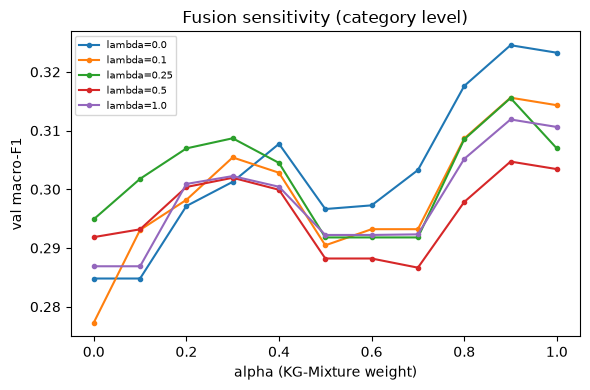

In [49]:
base = max([n for n in FITTED], key=lambda n: VAL[n]["macroF1"])
print("fusion base:", base)
Pb_va, Pb_te = FITTED[base][1], PC[base]
a_m, t_m = KG_BEST["KG-Mixture"]
Lk_va, Lk_te = np.log(kg_mixture(Xva, a_m, t_m) + 1e-9), np.log(PC["KG-Mixture"] + 1e-9)
fuse = lambda Pb, Lk, cs, a, lam: softmax((1 - a) * np.log(Pb + 1e-9) + a * Lk + lam * cs)

A_GRID, L_GRID = np.round(np.arange(0, 1.01, 0.1), 2), [0, 0.1, 0.25, 0.5, 1.0]
def search(cs_va, a_grid=A_GRID, l_grid=L_GRID):
    g = [(f1_score(yc[va], fuse(Pb_va, Lk_va, cs_va, a, l).argmax(1), labels=range(NC), average="macro", zero_division=0), a, l)
         for a in a_grid for l in l_grid]
    return max(g), pd.DataFrame(g, columns=["valF1", "alpha", "lambda"])

(f, A_BEST, L_BEST), GRID_RES = search(CSC["va"])
GRID_RES.to_csv(os.path.join(OUT_DIR, "fusion_grid.csv"), index=False)
CONFIGS = {"KG-Fusion": (CSC, A_BEST, L_BEST),
           "KG-Fusion w/o mixture": (CSC, 0.0, search(CSC["va"], a_grid=[0.0])[0][2]),
           "KG-Fusion w/o rules": (CSC, search(CSC["va"], l_grid=[0])[0][1], 0.0),
           "KG-Fusion (expert rules only)": (CSC_EXP, *search(CSC_EXP["va"])[0][1:])}
for name, (cs, a, l) in CONFIGS.items():
    VAL[name] = eval_cat(fuse(Pb_va, Lk_va, cs["va"], a, l), yc[va], name)
    PC[name] = fuse(Pb_te, Lk_te, cs["te"], a, l); TEST[name] = eval_cat(PC[name], yc[te], name)
    print(f"{name:30s} alpha={a} lambda={l} val F1={VAL[name]['macroF1']:.3f} test F1={TEST[name]['macroF1']:.3f}")

piv = GRID_RES.pivot(index="alpha", columns="lambda", values="valF1")
fig, ax = plt.subplots(figsize=(6, 4))
for l in piv.columns:
    ax.plot(piv.index, piv[l], marker="o", ms=3, label=f"lambda={l}")
ax.set_xlabel("alpha (KG-Mixture weight)"); ax.set_ylabel("val macro-F1"); ax.legend(fontsize=7)
ax.set_title("Fusion sensitivity (category level)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fusion_sensitivity.png"), dpi=200); plt.show()

## 8. DermKG-Net (GNN, hierarchical loss)

A GNN encodes the disease-level KG (concepts, groups, diseases, categories, supers, rules; no image nodes). An image is encoded from KG-contextualized concept embeddings, scored against disease node embeddings, and category logits are obtained along `IS_A`:
$$s_d(x)=\gamma\cos(z,H_d),\qquad s_k(x)=\log\sum_{d\in k}e^{s_d(x)},\qquad \mathcal L=\mathrm{CE}_w(s_k,y_k)+\beta\,\mathrm{CE}(s_d,y_d)$$
$\mathrm{CE}_w$ is class-weighted to counter the category skew. Dense adjacency in plain PyTorch, so PyTorch Geometric is not required. Variants: noKG (identity adjacency), GCN, GCN w/o rules, GAT.

In [50]:
if RUN_GNN:
    import torch, torch.nn as nn, torch.nn.functional as F
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    KG_RELS = ["BELONGS_TO", "IS_A", "SUBCLASS_OF", "CHARACTERIZED_BY", "CO_OCCURS", "GOVERNED_BY", "INDICATES"]
    kg = triples[triples.relation.isin(KG_RELS)].copy()
    kg.loc[kg.relation == "CO_OCCURS", "weight"] /= kg.loc[kg.relation == "CO_OCCURS", "weight"].max()
    kg.loc[kg.relation == "INDICATES", "weight"] /= 3.0
    kg = kg[kg.weight > 0]
    NODES = sorted(set(kg["head"]) | set(kg["tail"]) | {f"Disease:{d}" for d in DISEASES} | {f"Concept:{c}" for c in CONCEPTS})
    N_IDX = {n: i for i, n in enumerate(NODES)}
    CON_IDX = torch.tensor([N_IDX[f"Concept:{c}"] for c in CONCEPTS])
    DIS_IDX = torch.tensor([N_IDX[f"Disease:{d}"] for d in DISEASES])
    print(f"device {DEVICE} | KG: {len(NODES)} nodes, {len(kg)} edges")

    def build_adj(drop_rules=False, identity=False):
        A = np.zeros((len(NODES), len(NODES)), dtype=np.float32)
        if not identity:
            e = kg[~kg.relation.isin(["GOVERNED_BY", "INDICATES"])] if drop_rules else kg
            np.maximum.at(A, (e["head"].map(N_IDX).values, e["tail"].map(N_IDX).values), e["weight"].values.astype(np.float32))
            A = np.maximum(A, A.T)
        return torch.tensor(A + np.eye(len(NODES), dtype=np.float32))

    class DenseGCN(nn.Module):
        def __init__(self, d): super().__init__(); self.lin = nn.Linear(d, d)
        def forward(self, H, A):
            dinv = A.sum(1).pow(-0.5); return (dinv[:, None] * A * dinv[None, :]) @ self.lin(H)

    class DenseGAT(nn.Module):
        def __init__(self, d, heads=4):
            super().__init__(); self.h, self.dh = heads, d // heads
            self.lin = nn.Linear(d, d, bias=False)
            self.a_src = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
            self.a_dst = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        def forward(self, H, A):
            Z = self.lin(H).view(-1, self.h, self.dh)
            e = (Z * self.a_dst).sum(-1)[:, None, :] + (Z * self.a_src).sum(-1)[None, :, :]
            e = F.leaky_relu(e, 0.2).masked_fill((A <= 0)[:, :, None], float("-inf"))
            att = torch.softmax(e, dim=1) * A[:, :, None]
            att = att / att.sum(1, keepdim=True).clamp_min(1e-9)
            return torch.einsum("ijh,jhd->ihd", att, Z).reshape(-1, self.h * self.dh)

    class DermKGNet(nn.Module):
        def __init__(self, A, kind="gcn", d=128, layers=2, dropout=0.3):
            super().__init__()
            self.register_buffer("A", A); self.register_buffer("con_idx", CON_IDX); self.register_buffer("dis_idx", DIS_IDX)
            self.register_buffer("d2c", torch.tensor(d2c))
            self.emb = nn.Parameter(torch.randn(A.shape[0], d) * 0.1)
            L = DenseGAT if kind == "gat" else DenseGCN
            self.gnn = nn.ModuleList([L(d) for _ in range(layers)]); self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
            self.wx = nn.Linear(len(CONCEPTS), d); self.ln = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
            self.gamma = nn.Parameter(torch.tensor(10.0))
        def forward(self, x):
            H = self.emb
            for g, n in zip(self.gnn, self.norms):
                H = n(H + self.drop(F.gelu(g(H, self.A))))
            z = self.ln(self.drop((x @ H[self.con_idx]) / x.sum(1, keepdim=True).clamp_min(1) + self.wx(x)))
            sd = self.gamma * F.normalize(z, dim=-1) @ F.normalize(H[self.dis_idx], dim=-1).T     # B x K
            sc = torch.stack([torch.logsumexp(sd[:, self.d2c == k], 1) for k in range(NC)], 1)  # B x NC
            return sc, sd

    CW = torch.tensor(len(ytr_c) / (NC * np.maximum(cnt_c, 1)), dtype=torch.float32)

    def train_gnn(kind, A, seed, beta=0.5, epochs=400, lr=3e-3, wd=1e-4, patience=60):
        torch.manual_seed(seed); np.random.seed(seed)
        m = DermKGNet(A, kind).to(DEVICE); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
        xt = torch.tensor(Xtr, device=DEVICE); yct = torch.tensor(ytr_c, device=DEVICE); ydt = torch.tensor(ytr_d, device=DEVICE)
        xv, cw = torch.tensor(Xva, device=DEVICE), CW.to(DEVICE)
        best, state, wait = -1, None, 0
        for ep in range(epochs):
            m.train()
            for b in torch.randperm(len(xt), device=DEVICE).split(256):
                sc, sd = m(xt[b])
                loss = F.cross_entropy(sc, yct[b], weight=cw) + beta * F.cross_entropy(sd, ydt[b], label_smoothing=0.1)
                opt.zero_grad(); loss.backward(); opt.step()
            if ep % 5 == 0:
                m.eval()
                with torch.no_grad():
                    f = f1_score(yc[va], m(xv)[0].argmax(1).cpu().numpy(), labels=range(NC), average="macro", zero_division=0)
                if f > best:
                    best, wait, state = f, 0, {k: v.detach().clone() for k, v in m.state_dict().items()}
                else:
                    wait += 5
                    if wait >= patience:
                        break
        m.load_state_dict(state); m.eval()
        return m

    @torch.no_grad()
    def gnn_out(m, Xq):
        sc, sd = m(torch.tensor(Xq, device=DEVICE))
        return torch.softmax(sc, 1).cpu().numpy(), torch.softmax(sd, 1).cpu().numpy()

    VARIANTS = {"DermKG-Net (noKG)": ("gcn", build_adj(identity=True)), "DermKG-Net (GCN)": ("gcn", build_adj()),
                "DermKG-Net (GCN w/o rules)": ("gcn", build_adj(drop_rules=True)), "DermKG-Net (GAT)": ("gat", build_adj())}
    for name, (kind, A) in VARIANTS.items():
        t0, runs = time.time(), []
        for s in GNN_SEEDS:
            m = train_gnn(kind, A.to(DEVICE), s)
            pv, _ = gnn_out(m, Xva); pc, pd_ = gnn_out(m, Xte)
            runs.append((eval_cat(pv, yc[va]), eval_cat(pc, yc[te]), pc, pd_))
        PC[name] = np.mean([r[2] for r in runs], 0); PD[name] = np.mean([r[3] for r in runs], 0)
        VAL[name] = {"model": name, **pd.DataFrame([r[0] for r in runs]).mean().to_dict()}
        per = pd.DataFrame([r[1] for r in runs])
        TEST[name] = {"model": name, **per.mean().to_dict(), "macroF1_std": per["macroF1"].std()}
        print(f"{name:28s} test F1 {per.macroF1.mean():.3f} +/- {per.macroF1.std():.3f} ({time.time() - t0:.0f}s)")
else:
    VARIANTS = {}

device cpu | KG: 215 nodes, 827 edges
DermKG-Net (noKG)            test F1 0.308 +/- 0.006 (24s)
DermKG-Net (GCN)             test F1 0.312 +/- 0.006 (19s)
DermKG-Net (GCN w/o rules)   test F1 0.326 +/- 0.013 (24s)
DermKG-Net (GAT)             test F1 0.309 +/- 0.005 (51s)


## 9. Main results (test, category level)

In [51]:
ORDER = [n for n in FITTED] + ["KG-Rule", "KG-CatProfile", "KG-Mixture", "KG-Fusion w/o mixture", "KG-Fusion w/o rules",
                               "KG-Fusion (expert rules only)", "KG-Fusion"] + list(VARIANTS)
res = pd.DataFrame([TEST[n] for n in ORDER if n in TEST]).set_index("model")
res["family"] = ["baseline" if n in FITTED else "GNN" if n.startswith("DermKG") else "KG" for n in res.index]
res["F1_CI95"] = ["[%.3f, %.3f]" % tuple(boot_ci(PC[n], yc[te], "macroF1")) for n in res.index]
res["balAcc_CI95"] = ["[%.3f, %.3f]" % tuple(boot_ci(PC[n], yc[te], "balAcc")) for n in res.index]
cols = ["family", "macroF1", "F1_CI95", "balAcc", "balAcc_CI95", "acc", "minority_recall", "sup_balAcc"]
display(res[cols].round(3))
c = CEIL["category"]
print(f"reference: majority-class acc {c['majority_acc']:.3f} | acc ceiling {c['acc_ceiling']:.3f} | "
      f"balAcc ceiling {c['balacc_ceiling']:.3f} | chance balAcc {c['chance_balacc']:.3f}")
res.to_csv(os.path.join(OUT_DIR, "main_results_category.csv"))

,family,macroF1,F1_CI95,balAcc,balAcc_CI95,acc,minority_recall,sup_balAcc
model,,,,,,,,
LogReg (flat),baseline,0.256,"[0.202, 0.306]",0.224,"[0.185, 0.268]",0.677,0.133,0.443
BernoulliNB (flat),baseline,0.254,"[0.208, 0.293]",0.244,"[0.200, 0.290]",0.643,0.164,0.469
kNN (flat),baseline,0.217,"[0.179, 0.254]",0.206,"[0.174, 0.239]",0.572,0.135,0.433
RandomForest (flat),baseline,0.229,"[0.191, 0.266]",0.211,"[0.182, 0.245]",0.660,0.124,0.441
GradBoost (flat),baseline,0.261,"[0.217, 0.298]",0.236,"[0.201, 0.271]",0.680,0.149,0.463
MLP (flat),baseline,0.247,"[0.206, 0.282]",0.219,"[0.188, 0.251]",0.688,0.126,0.441
LogReg (bottomup),baseline,0.299,"[0.241, 0.347]",0.257,"[0.214, 0.306]",0.674,0.173,0.438
BernoulliNB (bottomup),baseline,0.250,"[0.204, 0.288]",0.219,"[0.184, 0.251]",0.674,0.129,0.435
kNN (bottomup),baseline,0.217,"[0.179, 0.254]",0.206,"[0.174, 0.239]",0.572,0.135,0.433


reference: majority-class acc 0.651 | acc ceiling 0.776 | balAcc ceiling 0.623 | chance balAcc 0.111


In [52]:
# paired bootstrap: best KG / GNN model vs best baseline, on macro-F1 and balanced accuracy
best_base = res.loc[res.family == "baseline", "macroF1"].idxmax()
best_kg = res.loc[res.family != "baseline", "macroF1"].idxmax()
r = np.random.default_rng(SEED); yt = yc[te]
pa, pb = PC[best_kg].argmax(1), PC[best_base].argmax(1)
dF, dB = [], []
for _ in range(N_BOOT):
    i = r.integers(0, len(yt), len(yt))
    dF.append(f1_score(yt[i], pa[i], labels=range(NC), average="macro", zero_division=0)
              - f1_score(yt[i], pb[i], labels=range(NC), average="macro", zero_division=0))
    dB.append(balanced_accuracy_score(yt[i], pa[i]) - balanced_accuracy_score(yt[i], pb[i]))
SIG = {}
for nm, d in (("macroF1", np.array(dF)), ("balAcc", np.array(dB))):
    SIG[nm] = dict(delta=d.mean(), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5), p_le0=(d <= 0).mean())
    print(f"{best_kg} vs {best_base} | {nm}: {d.mean():+.3f} [{SIG[nm]['lo']:+.3f}, {SIG[nm]['hi']:+.3f}], P(delta<=0)={SIG[nm]['p_le0']:.3f}")

DermKG-Net (GCN w/o rules) vs LogReg (bottomup) | macroF1: +0.024 [-0.029, +0.080], P(delta<=0)=0.208
DermKG-Net (GCN w/o rules) vs LogReg (bottomup) | balAcc: +0.150 [+0.073, +0.231], P(delta<=0)=0.000


## 10. Per-category analysis

,LogReg (bottomup),KG-Mixture,KG-Fusion,DermKG-Net (GCN),n_train
inflammatory,0.924,0.943,0.943,0.605,1470
malignant epidermal,0.197,0.311,0.311,0.492,211
genodermatoses,0.341,0.341,0.341,0.341,152
benign epidermal,0.125,0.100,0.100,0.375,142
benign dermal,0.189,0.108,0.108,0.162,125
malignant melanoma,0.333,0.333,0.333,0.476,76
benign melanocyte,0.200,0.000,0.000,0.700,34
malignant cutaneous lymphoma,0.000,0.000,0.000,0.000,31
malignant dermal,0.000,0.000,0.000,0.400,18


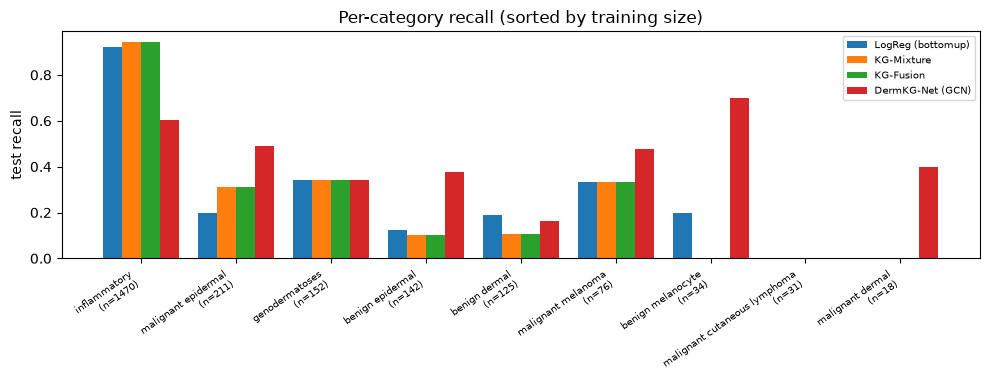

In [53]:
SHOW = list(dict.fromkeys([best_base, "KG-Mixture", "KG-Fusion", "DermKG-Net (GCN)"]))
SHOW = [s for s in SHOW if s in PC]
per_cat = pd.DataFrame({n: recall_score(yc[te], PC[n].argmax(1), labels=range(NC), average=None, zero_division=0) for n in SHOW},
                       index=CATS)
per_cat["n_train"] = cnt_c
per_cat = per_cat.sort_values("n_train", ascending=False)
display(per_cat.round(3))
per_cat.to_csv(os.path.join(OUT_DIR, "per_category_recall.csv"))

fig, ax = plt.subplots(figsize=(10, 4)); w = 0.8 / len(SHOW)
for k, n in enumerate(SHOW):
    ax.bar(np.arange(NC) + k * w, per_cat[n].values, w, label=n)
ax.set_xticks(np.arange(NC) + 0.4 - w / 2)
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(per_cat.index, per_cat.n_train)], rotation=35, ha="right", fontsize=7)
ax.set_ylabel("test recall"); ax.legend(fontsize=7); ax.set_title("Per-category recall (sorted by training size)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "per_category_recall.png"), dpi=200); plt.show()

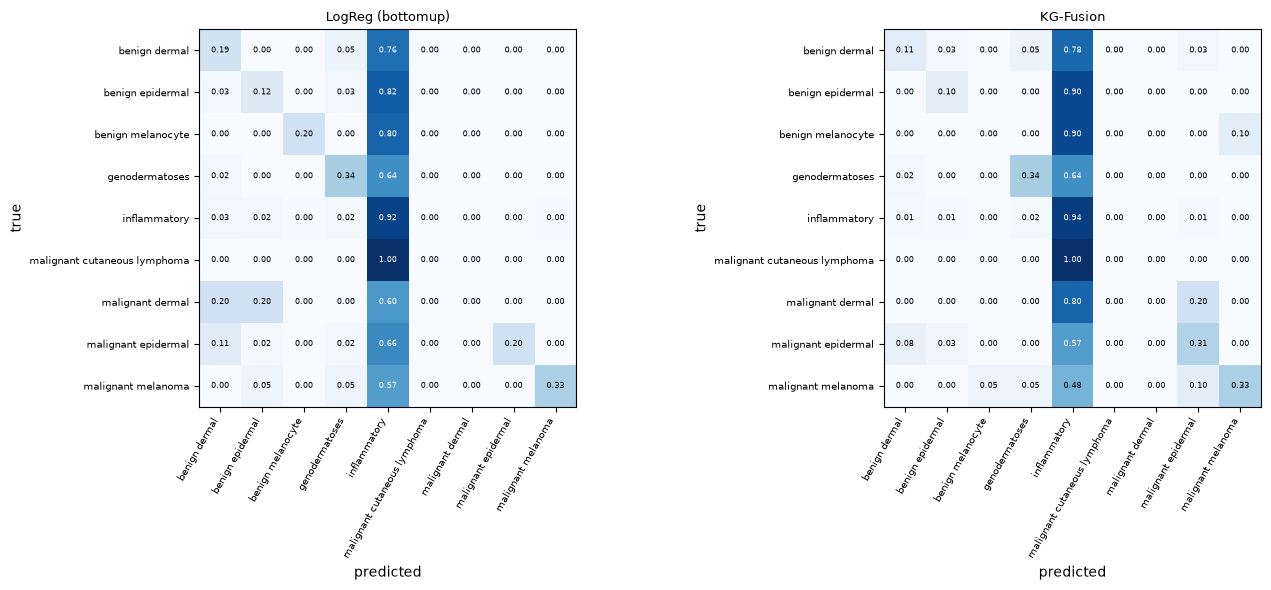

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, n in zip(axes, [best_base, "KG-Fusion"]):
    cm = confusion_matrix(yc[te], PC[n].argmax(1), labels=range(NC), normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NC)); ax.set_xticklabels(CATS, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(NC)); ax.set_yticklabels(CATS, fontsize=7)
    for i, j in itertools.product(range(NC), repeat=2):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cm[i, j] > 0.5 else "black")
    ax.set_title(n, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "category_confusion.png"), dpi=200); plt.show()

## 11. Secondary: super-category and fine-grained differential diagnosis

Super-category from category probabilities (`SUBCLASS_OF`). Fine-grained top-5 is reported only for models that produce disease probabilities.

In [55]:
sec = pd.DataFrame({n: {"sup_acc": TEST[n]["sup_acc"], "sup_balAcc": TEST[n]["sup_balAcc"]} for n in res.index}).T
for n in sec.index:
    if n in PD:
        for k, v in eval_dis(PD[n], yd[te]).items():
            sec.loc[n, k] = v
display(sec.round(3))
print(f"super ceiling: acc {CEIL['super']['acc_ceiling']:.3f}, balAcc {CEIL['super']['balacc_ceiling']:.3f} | "
      f"disease ceiling: acc {CEIL['disease']['acc_ceiling']:.3f}")
sec.to_csv(os.path.join(OUT_DIR, "secondary_results.csv"))

,sup_acc,sup_balAcc,dis_top1,dis_top5,dis_macroF1
LogReg (flat),0.740,0.443,NaN,NaN,NaN
BernoulliNB (flat),0.703,0.469,NaN,NaN,NaN
kNN (flat),0.645,0.433,NaN,NaN,NaN
RandomForest (flat),0.723,0.441,NaN,NaN,NaN
GradBoost (flat),0.740,0.463,NaN,NaN,NaN
MLP (flat),0.745,0.441,NaN,NaN,NaN
LogReg (bottomup),0.730,0.438,0.121,0.332,0.099
BernoulliNB (bottomup),0.740,0.435,0.178,0.372,0.114
kNN (bottomup),0.645,0.433,0.136,0.260,0.098
RandomForest (bottomup),0.699,0.423,0.124,0.300,0.103


super ceiling: acc 0.822, balAcc 0.722 | disease ceiling: acc 0.389


## 12. Skin-type breakdown (balanced accuracy, category level)

In [56]:
st = df.loc[te, "skin_type"].values
fst = pd.DataFrame({n: {t: balanced_accuracy_score(yc[te][st == t], PC[n].argmax(1)[st == t]) for t in sorted(set(st))}
                    for n in SHOW})
fst["n_test"] = pd.Series(Counter(st))
display(fst.round(3))
fst.to_csv(os.path.join(OUT_DIR, "skin_type_breakdown.csv"))

,LogReg (bottomup),KG-Mixture,KG-Fusion,DermKG-Net (GCN),n_test
FST-1,0.242,0.226,0.226,0.293,106
FST-2,0.181,0.198,0.198,0.401,191
FST-3,0.301,0.251,0.251,0.333,131
FST-4,0.267,0.245,0.245,0.457,107
FST-5,0.326,0.293,0.293,0.343,75
FST-6,0.467,0.254,0.254,0.304,23
FST-unknown,0.310,0.310,0.310,0.252,14


## 13. Explainability

**Case level.** KG-Mixture explains a category prediction by the disease that dominates the mixture and the concepts that separate it from the runner-up category's best disease:
$$\Delta_c=x_c\log\frac{p_{d^*}(c)}{p_{d'}(c)}+(1-x_c)\log\frac{1-p_{d^*}(c)}{1-p_{d'}(c)}$$
plus the activated expert rules that point into the predicted category.

KG-Fusion predictions backed by >= 1 expert rule: 0.374
  balanced acc when rule-backed 0.290 | otherwise 0.200
true: benign dermal (granuloma pyogenic)
pred: benign dermal (0.81) via pyogenic granuloma | runner-up: genodermatoses (0.16) via neurofibromatosis
present concepts: ['Nodule', 'Friable', 'Pedunculated', 'Erythema']
   + Friable                    +1.68
   + Erythema                   +1.40
   - Brown(Hyperpigmentation)   +1.15
   + Pedunculated               -0.79
   + Nodule                     -0.47
   - Papule                     -0.32
   rule R13 [strong] Friable erythematous papule/nodule -> pyogenic granuloma


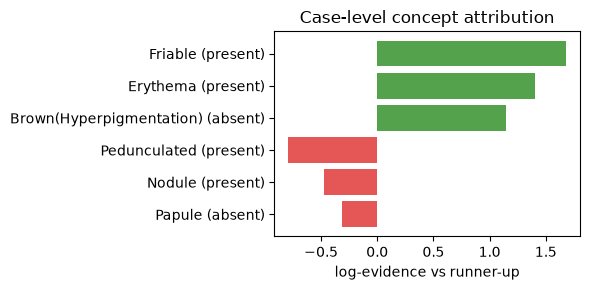

In [57]:
a_m, t_m = KG_BEST["KG-Mixture"]
_, P_D = hier_profiles(a_m)
pred_f = PC["KG-Fusion"].argmax(1)
rule_back = CSC_EXP["te"][np.arange(len(pred_f)), pred_f] > 0
print(f"KG-Fusion predictions backed by >= 1 expert rule: {rule_back.mean():.3f}")
print(f"  balanced acc when rule-backed {balanced_accuracy_score(yc[te][rule_back], pred_f[rule_back]):.3f} | "
      f"otherwise {balanced_accuracy_score(yc[te][~rule_back], pred_f[~rule_back]):.3f}")

def explain(i, topn=6):
    x = Xte[i]; P = PC["KG-Fusion"][i]; k1, k2 = np.argsort(-P)[:2]
    ll = bern_ll(x[None], P_D)[0] + np.log(np.maximum(cnt_d, 1))
    d1 = np.flatnonzero(d2c == k1)[ll[d2c == k1].argmax()]; d2 = np.flatnonzero(d2c == k2)[ll[d2c == k2].argmax()]
    p1, p2 = np.clip(P_D[d1], 1e-4, 1 - 1e-4), np.clip(P_D[d2], 1e-4, 1 - 1e-4)
    delta = x * np.log(p1 / p2) + (1 - x) * np.log((1 - p1) / (1 - p2))
    order = np.argsort(-np.abs(delta))[:topn]
    print(f"true: {CATS[yc[te][i]]} ({DISEASES[yd[te][i]]})")
    print(f"pred: {CATS[k1]} ({P[k1]:.2f}) via {DISEASES[d1]} | runner-up: {CATS[k2]} ({P[k2]:.2f}) via {DISEASES[d2]}")
    print("present concepts:", [CONCEPTS[j] for j in np.flatnonzero(x)])
    for j in order:
        print(f"   {'+' if x[j] else '-'} {CONCEPTS[j]:26s} {delta[j]:+.2f}")
    for r_ in np.flatnonzero(ACT_TE[i] & EXPERT):
        if any(d2c[D_IDX[d]] == k1 for d in rules.targets[r_]):
            print(f"   rule {rules.rule_id[r_]} [{rules.strength[r_]}] {rules.name[r_]}")
    return order, delta

minority_ok = np.flatnonzero((pred_f == yc[te]) & rule_back & (yc[te] != CATS.index("inflammatory")))
case = minority_ok[0] if len(minority_ok) else np.flatnonzero(pred_f == yc[te])[0]
order, delta = explain(case)
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh([CONCEPTS[j] + (" (present)" if Xte[case, j] else " (absent)") for j in order][::-1], delta[order][::-1],
        color=["#54a24b" if v > 0 else "#e45756" for v in delta[order][::-1]])
ax.set_xlabel("log-evidence vs runner-up"); ax.set_title("Case-level concept attribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "case_attribution.png"), dpi=200); plt.show()

## 14. Error analysis

In [58]:
err = pred_f != yc[te]
print(f"KG-Fusion category errors: {err.sum()} / {len(err)}")
print(f"  errors within the true super-category: {(c2s[pred_f[err]] == c2s[yc[te][err]]).mean():.3f}")
seen = {}
for k_, c_ in zip(key[tr], yc[tr]):
    seen.setdefault(k_, set()).add(c_)
amb = np.array([pred_f[i] in seen.get(key[te][i], set()) for i in np.flatnonzero(err)])
print(f"  errors whose concept vector appears with the predicted category in train: {amb.mean():.3f}")
pairs = Counter((CATS[a], CATS[b]) for a, b in zip(yc[te][err], pred_f[err]))
conf = pd.DataFrame([(a, b, n) for (a, b), n in pairs.most_common(10)], columns=["true", "predicted", "count"])
display(conf); conf.to_csv(os.path.join(OUT_DIR, "top_confusions.csv"), index=False)

KG-Fusion category errors: 202 / 647
  errors within the true super-category: 0.198
  errors whose concept vector appears with the predicted category in train: 0.708


,true,predicted,count
0,benign epidermal,inflammatory,36
1,malignant epidermal,inflammatory,35
2,benign dermal,inflammatory,29
3,genodermatoses,inflammatory,28
4,malignant melanoma,inflammatory,10
5,malignant cutaneous lymphoma,inflammatory,9
6,benign melanocyte,inflammatory,9
7,inflammatory,genodermatoses,8
8,inflammatory,malignant epidermal,6
9,malignant epidermal,benign dermal,5


## 15. Save

In [59]:
summary = {"ceilings": CEIL, "fusion": {"base": base, "alpha": float(A_BEST), "lambda": float(L_BEST)},
           "kg_mixture": {"alpha2": KG_BEST["KG-Mixture"][0], "tau": KG_BEST["KG-Mixture"][1]},
           "best_baseline": best_base, "best_kg": best_kg, "significance": SIG,
           "test": {n: {k: v for k, v in TEST[n].items() if k != "model"} for n in res.index}}
json.dump(summary, open(os.path.join(OUT_DIR, "summary.json"), "w"), indent=1, default=float)
np.savez_compressed(os.path.join(OUT_DIR, "test_probs.npz"), y_cat=yc[te], y_dis=yd[te],
                    **{f"cat__{n}": PC[n] for n in res.index}, **{f"dis__{n}": PD[n] for n in PD})
print("saved:", sorted(os.listdir(OUT_DIR)))

saved: ['ceilings.csv', 'figures', 'fusion_grid.csv', 'main_results_category.csv', 'per_category_recall.csv', 'secondary_results.csv', 'skin_type_breakdown.csv', 'summary.json', 'test_probs.npz', 'top_confusions.csv']
